# Course 2 — LSTM Autoencoder Anomaly Scoring (Corrected)

Corrections versus the first version:
* Label-clean segments are split **70 / 15 / 15 into train / validation / test** (by segment), so the
  test set now contains clean windows as well as anomaly windows. Test precision, F1, PR-AUC and ROC-AUC
  can therefore be reported (the first version could only report recall / "detection rate").
* Normalisation statistics are computed in float64 on training windows only, and normalised values are
  **clipped to ±10 σ**. Without clipping, channel_48 (σ ≈ 3·10⁻⁵) produced inputs of ~30 000 σ and
  reconstruction errors of ~10⁸ that dominated every downstream score.
* The threshold is selected on validation data only and then frozen for the test set.

In [1]:
import os, sys, random, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             confusion_matrix, classification_report, precision_score, recall_score, f1_score)

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
import rl_utils as U

OUT = PROJECT / "outputs"
C1 = OUT
LSTM_DIR = OUT / "05_lstm_autoencoder"; LSTM_DIR.mkdir(parents=True, exist_ok=True)
PLOTS = OUT / "04_plots"

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})

def save_show(name):
    plt.tight_layout(); plt.savefig(PLOTS / name, bbox_inches="tight"); plt.close()
    display(Image(filename=str(PLOTS / name)))

WINDOW = 128
CLIP = 10.0
print("TensorFlow", tf.__version__)

I0000 00:00:1794208675.538714     502 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


I0000 00:00:1794208676.526684     502 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load Course 1 outputs

In [2]:
telemetry_df = pd.read_parquet(C1 / "02_preprocessing" / "telemetry_90s_12channels.parquet")
known_mask = pd.read_parquet(C1 / "02_preprocessing" / "known_anomaly_mask.parquet")["known_anomaly"].to_numpy()
clean_segments = pd.read_csv(C1 / "02_preprocessing" / "label_clean_segments.csv", parse_dates=["Start", "End"])
labels = pd.read_csv(C1 / "01_dataset" / "selected_anomaly_labels.csv", parse_dates=["StartTime", "EndTime"])
split_ids = pd.read_csv(C1 / "03_splits" / "anomaly_event_split.csv")
CHANNELS = list(telemetry_df.columns)
N_CH = len(CHANNELS)
values = telemetry_df.to_numpy(dtype=np.float32)
index = telemetry_df.index
print("Telemetry:", telemetry_df.shape, "| clean segments:", len(clean_segments), "| events:", split_ids.shape[0])

Telemetry: (4909440, 12) | clean segments: 165 | events: 168


## 2. Label-clean windows: segment-level train / validation / test split

In [3]:
seg = clean_segments.copy()
seg["StartPos"] = index.searchsorted(seg["Start"]); seg["EndPos"] = index.searchsorted(seg["End"], side="right")
perm = np.random.RandomState(SEED).permutation(len(seg))
n_tr, n_va = int(len(seg) * 0.70), int(len(seg) * 0.15)
seg["Split"] = "Test"
seg.loc[seg.index[perm[:n_tr]], "Split"] = "Train"
seg.loc[seg.index[perm[n_tr:n_tr + n_va]], "Split"] = "Validation"

def clean_windows(split):
    out = []
    for s, e in seg.loc[seg.Split == split, ["StartPos", "EndPos"]].itertuples(index=False):
        k = (e - s) // WINDOW
        if k:
            w = values[s:s + k * WINDOW].reshape(k, WINDOW, N_CH)
            out.append(w[~np.isnan(w).any(axis=(1, 2))])
    return np.concatenate(out)

Xc = {s: clean_windows(s) for s in ["Train", "Validation", "Test"]}
clean_split_summary = pd.DataFrame({"Split": list(Xc), "Segments": [int((seg.Split == s).sum()) for s in Xc],
                                    "Clean_windows": [len(v) for v in Xc.values()]})
print(clean_split_summary.to_string(index=False))

     Split  Segments  Clean_windows
     Train       115          23700
Validation        24           5712
      Test        26           5282


## 3. Training-only normalisation (float64) with ±10 σ clipping

In [4]:
flat = Xc["Train"].reshape(-1, N_CH).astype(np.float64)
mu, sd = flat.mean(axis=0), flat.std(axis=0)
del flat
def normalise(x):
    return np.clip((x - mu) / sd, -CLIP, CLIP).astype(np.float32)

X = {s: normalise(v) for s, v in Xc.items()}
norm_stats = pd.DataFrame({"Channel": CHANNELS, "Mean": mu, "Std": sd,
                           "Train_clipped_%": [(np.abs((Xc["Train"][:, :, i] - mu[i]) / sd[i]) > CLIP).mean() * 100 for i in range(N_CH)]})
print(norm_stats.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
print("\nNormalised training mean:", X["Train"].reshape(-1, N_CH).mean(0).round(3))
print("Normalised training std :", X["Train"].reshape(-1, N_CH).std(0).round(3))

   Channel       Mean         Std  Train_clipped_%
channel_41   0.809734  0.00487795      0.000296677
channel_45   0.811911  0.00545023      0.000296677
channel_43   0.770249  0.00519377      0.000296677
channel_14   0.269603   0.0882853                0
channel_21   0.276061    0.089652                0
channel_29   0.289523   0.0835091                0
channel_48 0.00184803 3.03303e-05                0
channel_52   0.757827   0.0130642                0
channel_31   0.330635   0.0633724                0
channel_22   0.332212   0.0633285                0
channel_39   0.334975   0.0644132                0
channel_15   0.118421    0.061542                0

Normalised training mean: [ 0.     0.     0.    -0.    -0.001  0.     0.    -0.     0.    -0.
  0.    -0.001]


Normalised training std : [0.998 0.998 0.997 1.    0.999 1.    1.    1.    0.999 0.999 0.998 1.   ]


## 4. LSTM autoencoder (128 × 12 → 64 → 16 → 64 → 128 × 12)

In [5]:
inp = tf.keras.Input(shape=(WINDOW, N_CH))
h = tf.keras.layers.LSTM(64)(inp)
z = tf.keras.layers.Dense(16, name="latent")(h)
r = tf.keras.layers.RepeatVector(WINDOW)(z)
r = tf.keras.layers.LSTM(64, return_sequences=True)(r)
outp = tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(N_CH))(r)
ae = tf.keras.Model(inp, outp, name="LSTM_Autoencoder")
ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
ae.summary()

Model: "LSTM_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 12)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 128, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128, 64)        │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 128, 12)        │           780 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,268 (165.11 KB)

 Trainable params: 42,268 (165.11 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


E0000 00:00:1794208683.500289     502 util.cc:131] oneDNN supports DT_INT32 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


371/371 - 46s - 124ms/step - loss: 0.2548 - val_loss: 0.2017


Epoch 2/100


371/371 - 40s - 108ms/step - loss: 0.2004 - val_loss: 0.0904


Epoch 3/100


... (192 outputs left out)

371/371 - 40s - 108ms/step - loss: 0.0147 - val_loss: 0.0147


Epoch 100/100


371/371 - 40s - 107ms/step - loss: 0.0147 - val_loss: 0.0150



Training time: 69.0 min | epochs run: 100 | best epoch: 89 | best val MSE: 0.014543


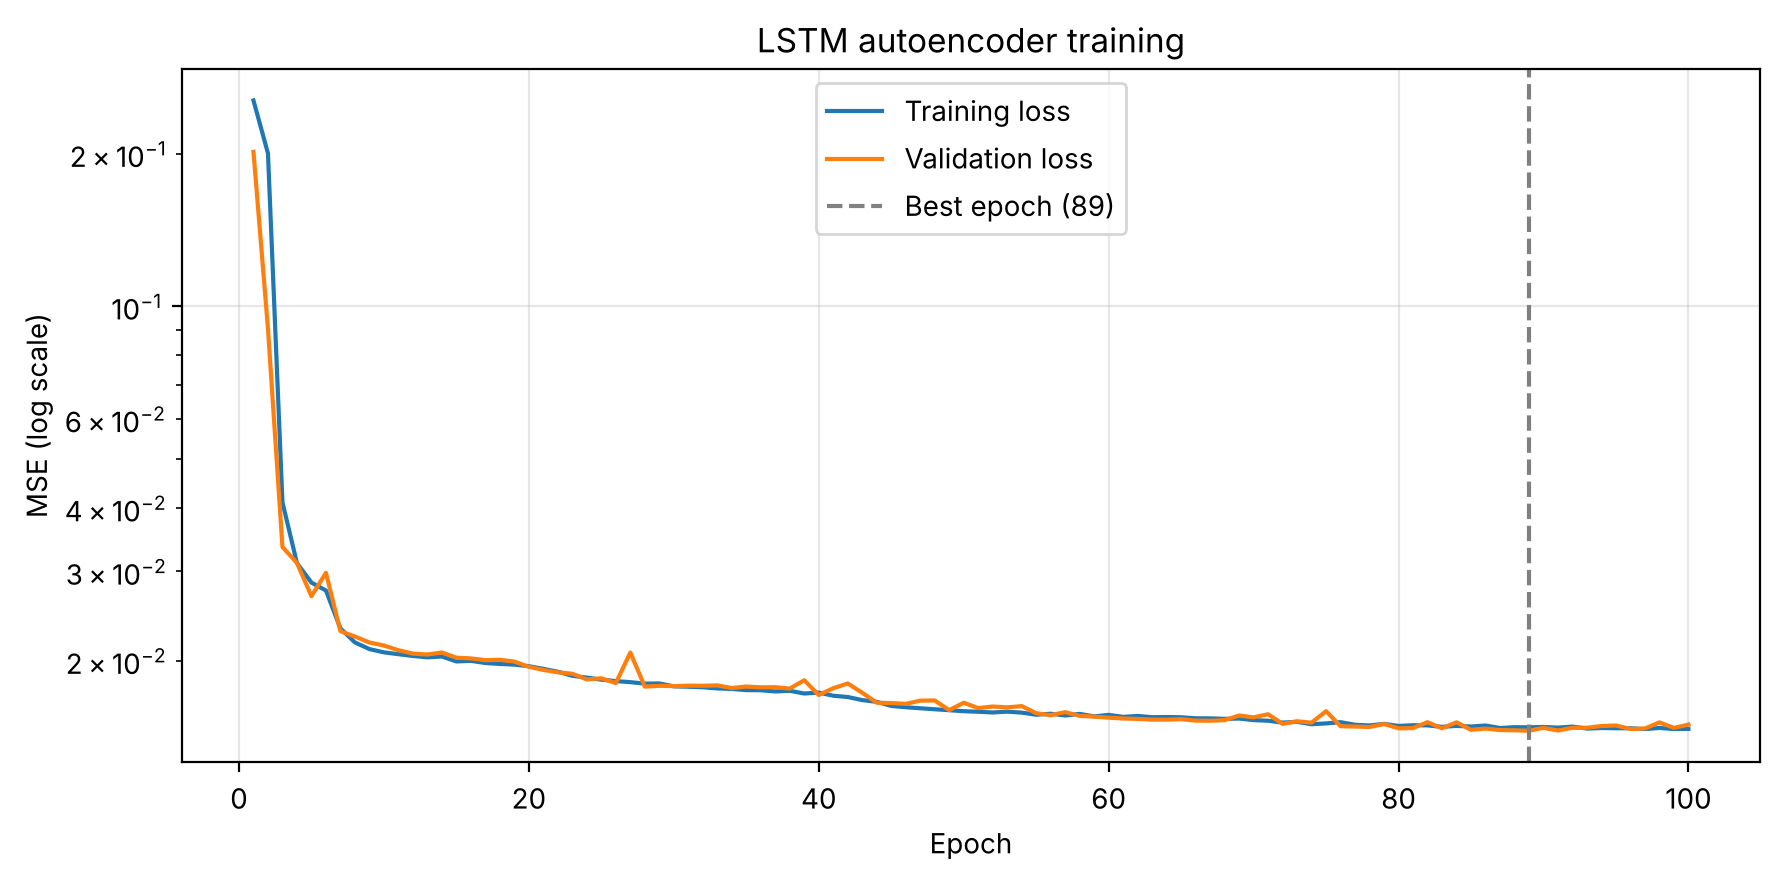

In [6]:
MAX_EPOCHS, BATCH, PATIENCE = 100, 64, 12
t0 = time.time()
history = ae.fit(X["Train"], X["Train"], validation_data=(X["Validation"], X["Validation"]),
                 epochs=MAX_EPOCHS, batch_size=BATCH, shuffle=True, verbose=2,
                 callbacks=[tf.keras.callbacks.EarlyStopping("val_loss", patience=PATIENCE, restore_best_weights=True),
                            tf.keras.callbacks.CSVLogger(str(LSTM_DIR / "epoch_log.csv"))])
hist = pd.DataFrame(history.history); hist.index = hist.index + 1
best_epoch = int(hist["val_loss"].idxmin())
print(f"\nTraining time: {(time.time()-t0)/60:.1f} min | epochs run: {len(hist)} | best epoch: {best_epoch} "
      f"| best val MSE: {hist['val_loss'].min():.6f}")

plt.figure(figsize=(9, 4.5))
plt.plot(hist.index, hist["loss"], label="Training loss"); plt.plot(hist.index, hist["val_loss"], label="Validation loss")
plt.axvline(best_epoch, ls="--", color="grey", label=f"Best epoch ({best_epoch})")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE (log scale)"); plt.title("LSTM autoencoder training"); plt.legend()
save_show("06_lstm_training_validation_loss.png")

## 5. Anomaly windows for validation and test events
Windows are taken on the global 128-sample grid; a window is an *anomaly window* of a split if it overlaps
any annotation of an event in that split. Windows containing unresolved NaNs are excluded (counted below).

In [7]:
n_global = len(values) // WINDOW
gwin = values[:n_global * WINDOW].reshape(n_global, WINDOW, N_CH)
g_nan = np.isnan(gwin).any(axis=(1, 2))

def anomaly_windows(split):
    ids = set(split_ids.loc[split_ids.Split == split, "ID"])
    lab = labels[labels.ID.isin(ids)]
    m = U.interval_mask(index, lab["StartTime"].values, lab["EndTime"].values)[:n_global * WINDOW]
    hit = m.reshape(n_global, WINDOW).any(axis=1)
    return np.where(hit & ~g_nan)[0], int((hit & g_nan).sum())

anom_ids, anom_rows = {}, []
for s in ["Validation", "Test"]:
    ids, excl = anomaly_windows(s); anom_ids[s] = ids
    anom_rows.append({"Split": s, "Anomaly_windows_valid": len(ids), "Excluded_NaN": excl})
print(pd.DataFrame(anom_rows).to_string(index=False))

def recon_errors(xn):
    rec = ae.predict(xn, batch_size=512, verbose=0)
    ch = np.mean((xn - rec) ** 2, axis=1)          # (n, 12) channel-wise errors
    return ch.mean(axis=1), ch

err, ch_err, y = {}, {}, {}
for s in ["Validation", "Test"]:
    xa = normalise(gwin[anom_ids[s]])
    e_c, c_c = recon_errors(X[s]); e_a, c_a = recon_errors(xa)
    err[s] = np.concatenate([e_c, e_a]); ch_err[s] = np.concatenate([c_c, c_a])
    y[s] = np.concatenate([np.zeros(len(e_c), int), np.ones(len(e_a), int)])
    print(f"{s}: clean windows {len(e_c)}, anomaly windows {len(e_a)} | median error clean {np.median(e_c):.4f}, anomaly {np.median(e_a):.4f}")

     Split  Anomaly_windows_valid  Excluded_NaN
Validation                    740            10
      Test                    491             1


Validation: clean windows 5712, anomaly windows 740 | median error clean 0.0145, anomaly 0.0183


Test: clean windows 5282, anomaly windows 491 | median error clean 0.0145, anomaly 0.0167


## 6. Threshold selection on validation (max F1), frozen for test

In [8]:
p, r, t = precision_recall_curve(y["Validation"], err["Validation"])
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
bi = int(np.argmax(f1)); THRESHOLD = float(t[bi])
print(f"Selected threshold: {THRESHOLD:.6f}")

rows = []
for s in ["Validation", "Test"]:
    pred = (err[s] >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[s], pred).ravel()
    rows.append({"Split": s, "Clean_windows": int((y[s] == 0).sum()), "Anomaly_windows": int(y[s].sum()),
                 "Threshold": THRESHOLD, "Precision": precision_score(y[s], pred), "Recall": recall_score(y[s], pred),
                 "F1": f1_score(y[s], pred), "PR_AUC": average_precision_score(y[s], err[s]),
                 "ROC_AUC": roc_auc_score(y[s], err[s]), "Accuracy": (pred == y[s]).mean(),
                 "False_positive_rate": fp / (fp + tn), "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    print(f"\n{s} classification report"); print(classification_report(y[s], pred, target_names=["Clean", "Anomaly"], digits=4))
lstm_results = pd.DataFrame(rows)
print(lstm_results.round(4).to_string(index=False))

Selected threshold: 0.018620

Validation classification report
              precision    recall  f1-score   support

       Clean     0.9376    0.9839    0.9602      5712
     Anomaly     0.7991    0.4946    0.6110       740

    accuracy                         0.9278      6452
   macro avg     0.8684    0.7392    0.7856      6452
weighted avg     0.9217    0.9278    0.9201      6452


Test classification report
              precision    recall  f1-score   support

       Clean     0.9465    0.9875    0.9666      5282
     Anomaly     0.7481    0.3992    0.5206       491

    accuracy                         0.9375      5773
   macro avg     0.8473    0.6933    0.7436      5773
weighted avg     0.9296    0.9375    0.9286      5773

     Split  Clean_windows  Anomaly_windows  Threshold  Precision  Recall     F1  PR_AUC  ROC_AUC  Accuracy  False_positive_rate   TN  FP  FN  TP
Validation           5712              740     0.0186     0.7991  0.4946 0.6110  0.6359   0.8100    0.9278    

## 7. Diagnostic plots

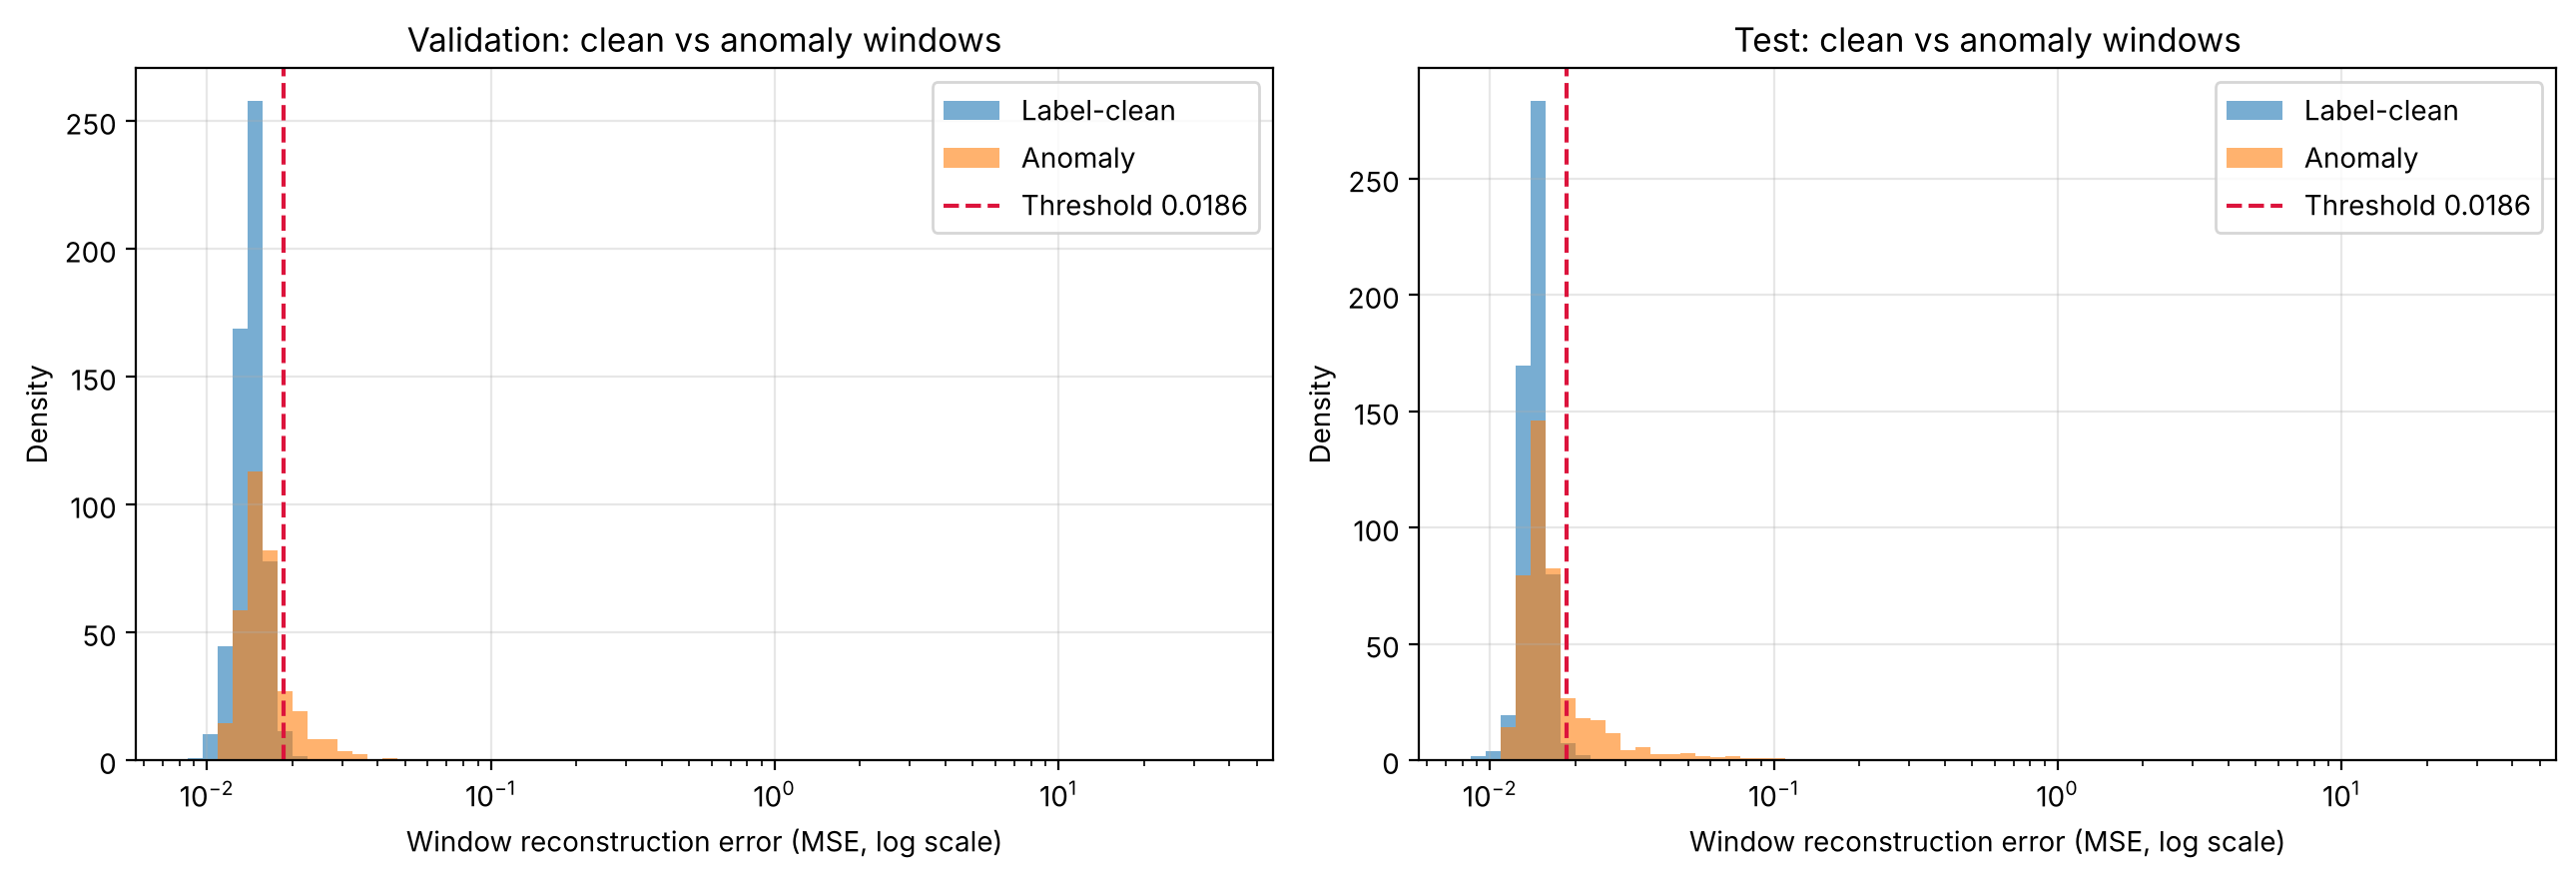

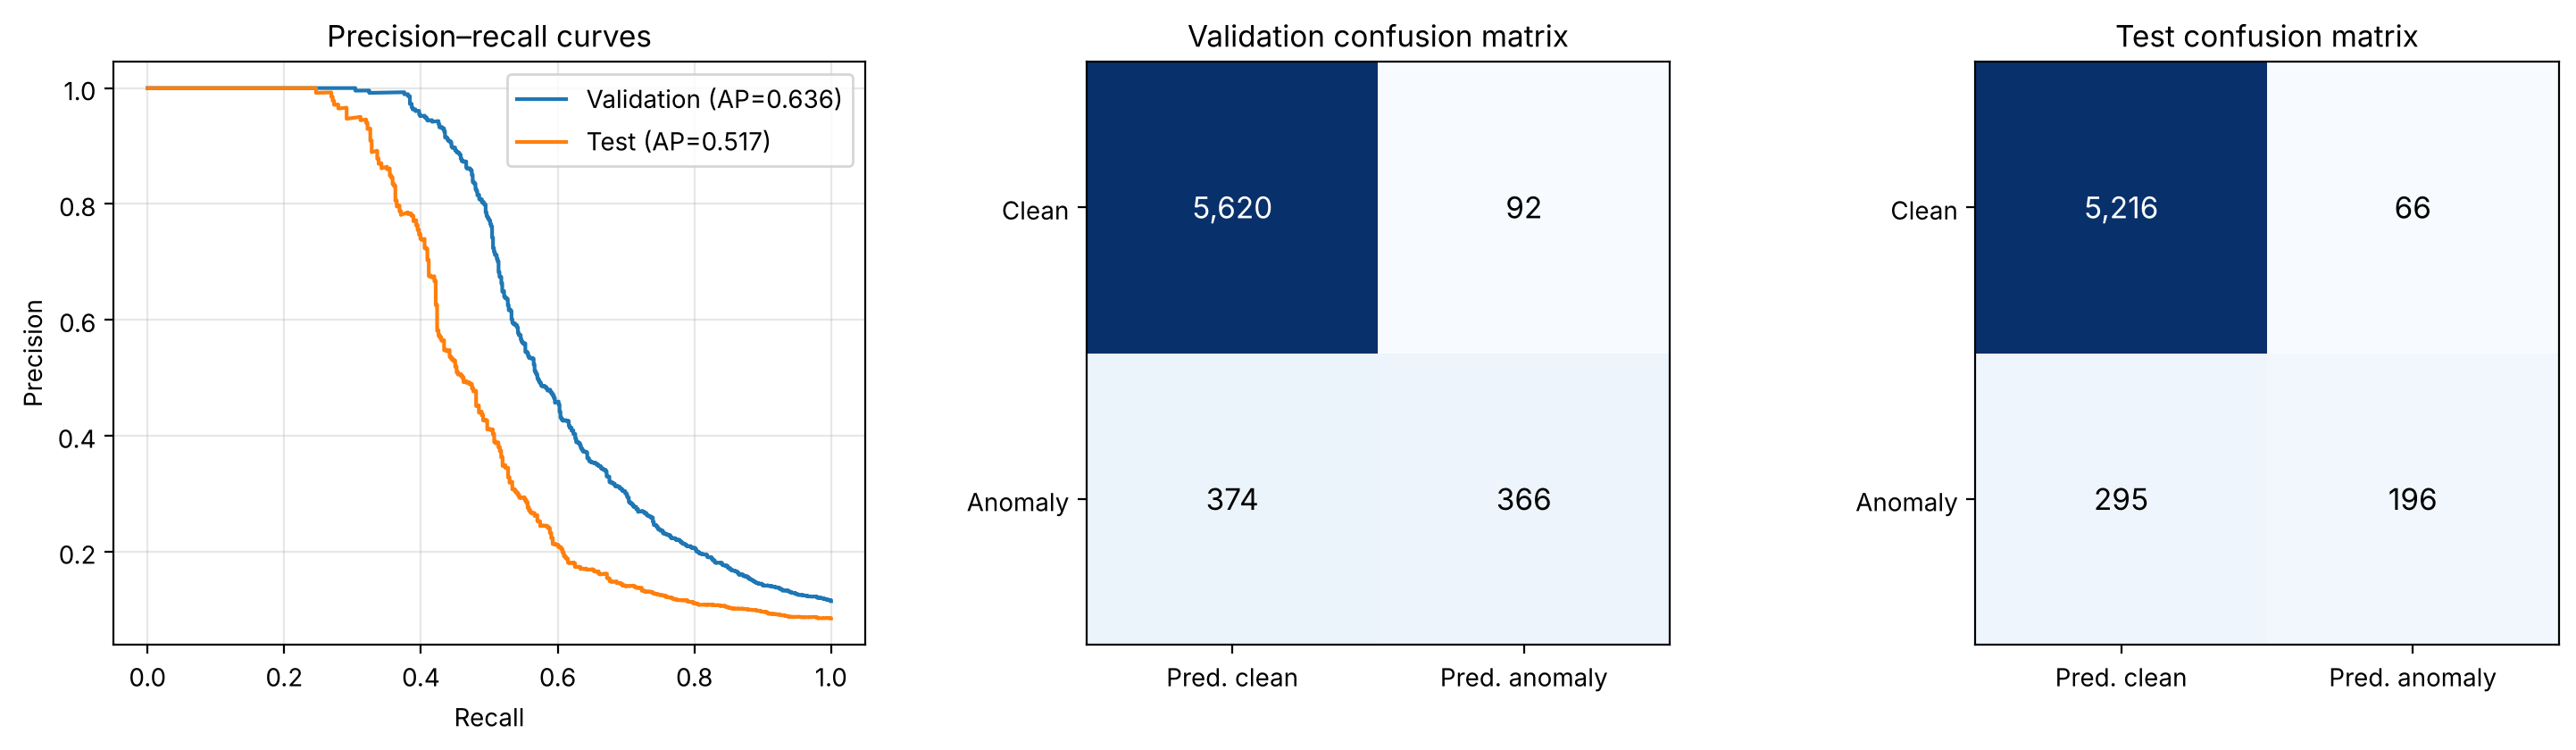

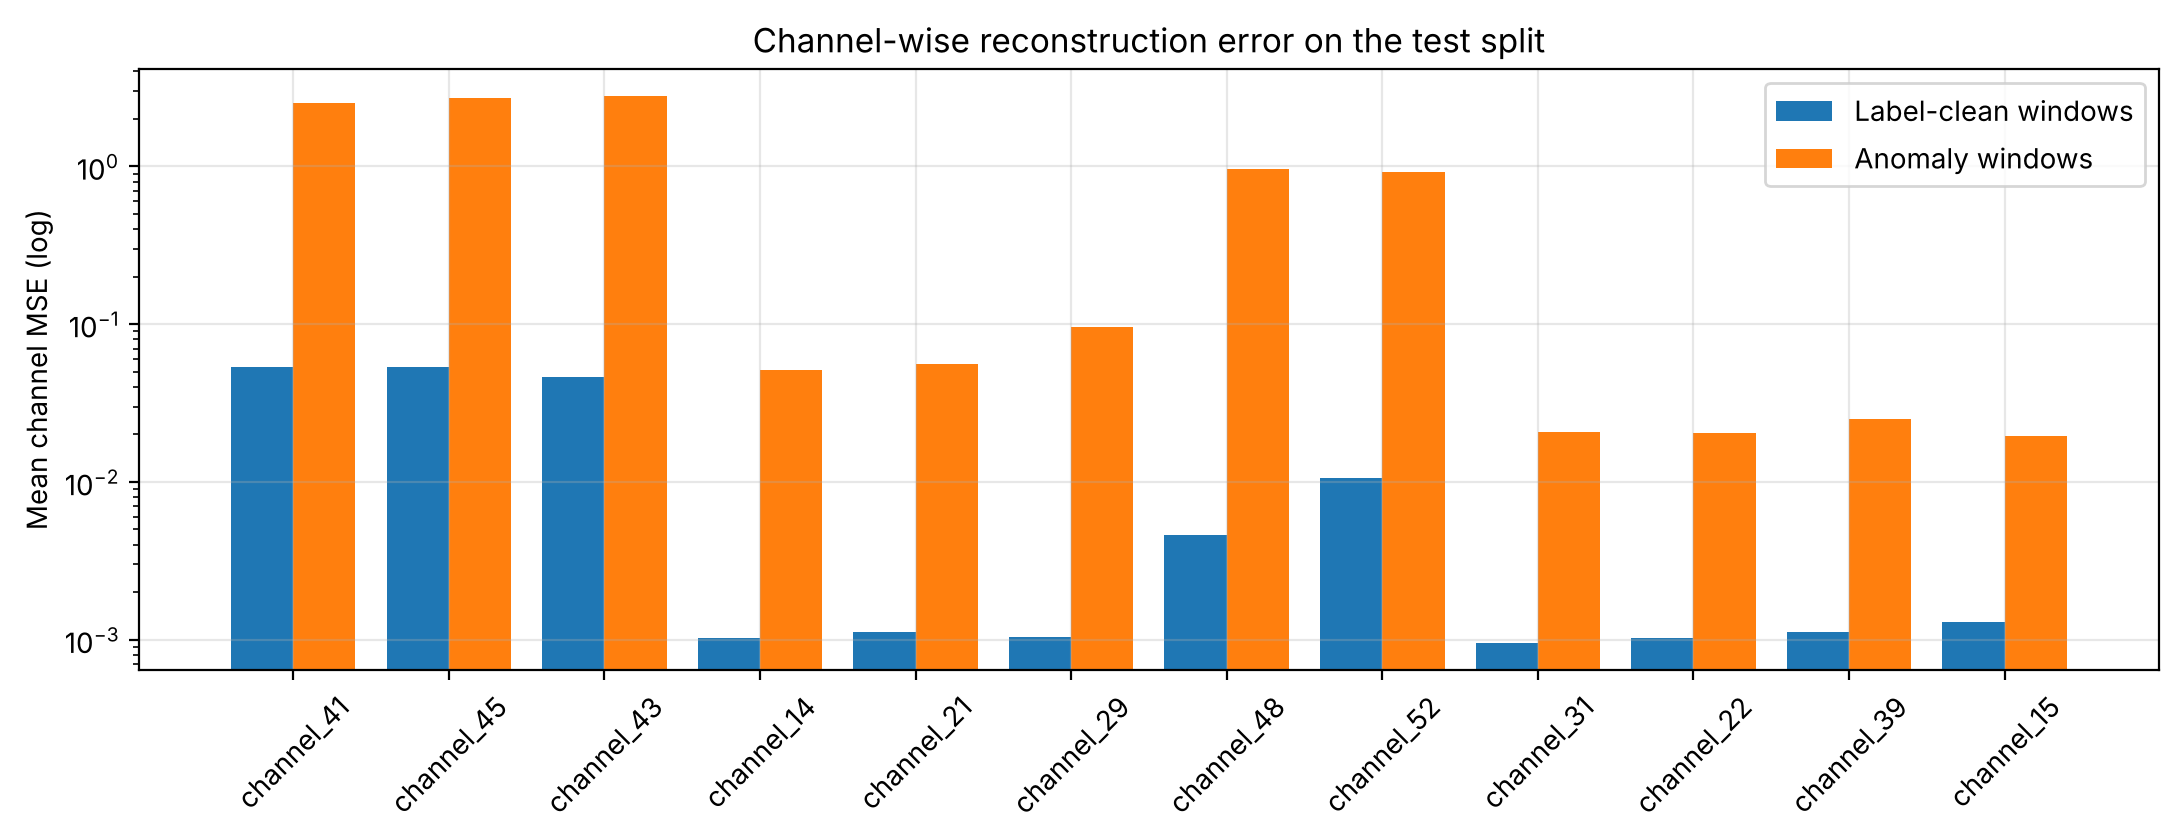

   Channel  Clean (test)  Anomaly (test)
channel_41        0.0534          2.5333
channel_45        0.0532          2.7031
channel_43        0.0460          2.7795
channel_14        0.0010          0.0510
channel_21        0.0011          0.0555
channel_29        0.0010          0.0965
channel_48        0.0046          0.9639
channel_52        0.0106          0.9190
channel_31        0.0010          0.0207
channel_22        0.0010          0.0204
channel_39        0.0011          0.0252
channel_15        0.0013          0.0195


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
bins = np.logspace(np.log10(min(err["Validation"].min(), err["Test"].min())), np.log10(max(err["Validation"].max(), err["Test"].max())), 70)
for a, s in zip(ax, ["Validation", "Test"]):
    a.hist(err[s][y[s] == 0], bins=bins, alpha=0.6, label="Label-clean", density=True)
    a.hist(err[s][y[s] == 1], bins=bins, alpha=0.6, label="Anomaly", density=True)
    a.axvline(THRESHOLD, color="crimson", ls="--", label=f"Threshold {THRESHOLD:.4f}")
    a.set_xscale("log"); a.set_xlabel("Window reconstruction error (MSE, log scale)"); a.set_ylabel("Density")
    a.set_title(f"{s}: clean vs anomaly windows"); a.legend()
save_show("07_reconstruction_error_distributions.png")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for s, c in [("Validation", "C0"), ("Test", "C1")]:
    pp, rr, _ = precision_recall_curve(y[s], err[s])
    ax[0].plot(rr, pp, color=c, label=f"{s} (AP={average_precision_score(y[s], err[s]):.3f})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision–recall curves"); ax[0].legend()
for a, s in zip(ax[1:], ["Validation", "Test"]):
    cm = confusion_matrix(y[s], (err[s] >= THRESHOLD).astype(int))
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    a.set_xticks([0, 1], ["Pred. clean", "Pred. anomaly"]); a.set_yticks([0, 1], ["Clean", "Anomaly"])
    a.set_title(f"{s} confusion matrix")
save_show("08_lstm_pr_curves_and_confusion_matrices.png")

ce = pd.DataFrame({"Channel": CHANNELS,
                   "Clean (test)": ch_err["Test"][y["Test"] == 0].mean(0),
                   "Anomaly (test)": ch_err["Test"][y["Test"] == 1].mean(0)})
xx = np.arange(N_CH)
plt.figure(figsize=(11, 4.3))
plt.bar(xx - 0.2, ce["Clean (test)"], 0.4, label="Label-clean windows"); plt.bar(xx + 0.2, ce["Anomaly (test)"], 0.4, label="Anomaly windows")
plt.yscale("log"); plt.xticks(xx, CHANNELS, rotation=45); plt.ylabel("Mean channel MSE (log)")
plt.title("Channel-wise reconstruction error on the test split"); plt.legend()
save_show("09_channelwise_reconstruction_error.png")
print(ce.round(4).to_string(index=False))

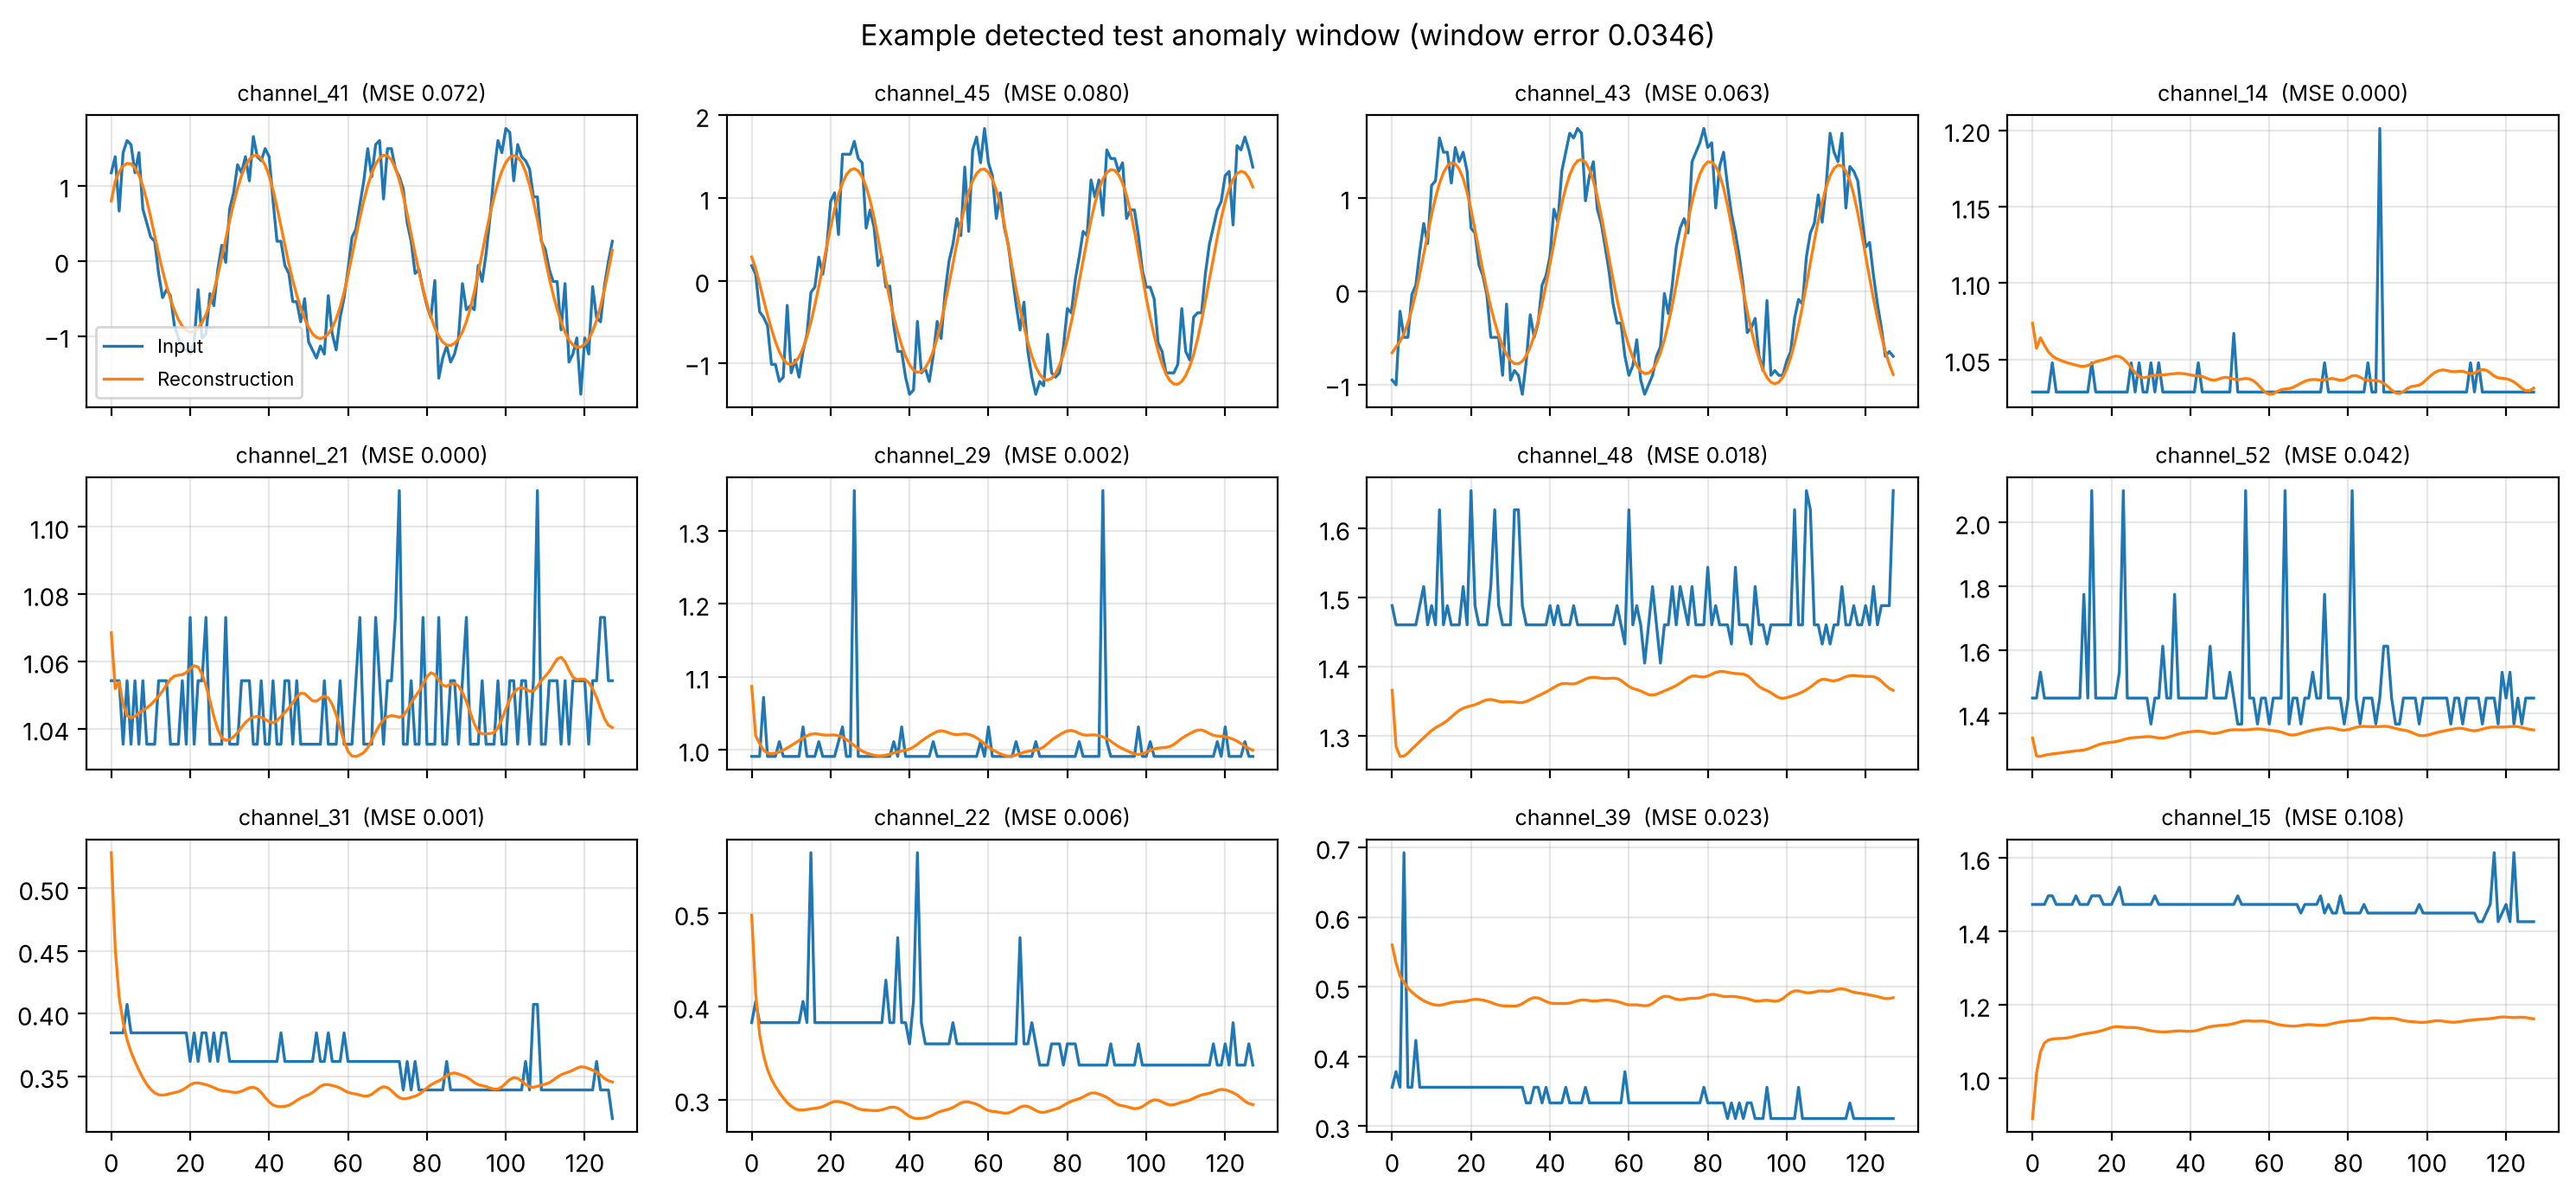

In [10]:
# Example reconstruction: the test anomaly window with the median error above threshold
a_err = err["Test"][y["Test"] == 1]; a_x = normalise(gwin[anom_ids["Test"]])
cand = np.where(a_err >= THRESHOLD)[0]
k = cand[np.argsort(a_err[cand])[len(cand) // 2]] if len(cand) else int(np.argmax(a_err))
rec = ae.predict(a_x[k:k + 1], verbose=0)[0]
fig, axs = plt.subplots(3, 4, figsize=(15, 7), sharex=True)
for i, a in enumerate(axs.ravel()):
    a.plot(a_x[k][:, i], lw=1.2, label="Input"); a.plot(rec[:, i], lw=1.2, label="Reconstruction")
    a.set_title(f"{CHANNELS[i]}  (MSE {np.mean((a_x[k][:, i]-rec[:, i])**2):.3f})", fontsize=9)
axs[0, 0].legend(fontsize=8)
fig.suptitle(f"Example detected test anomaly window (window error {a_err[k]:.4f})")
save_show("10_example_reconstruction.png")

## 8. Save Course 2 outputs

In [11]:
ae.save(LSTM_DIR / "lstm_autoencoder.keras")
norm_stats.to_csv(LSTM_DIR / "training_normalization_statistics.csv", index=False)
hist.rename_axis("Epoch").to_csv(LSTM_DIR / "lstm_training_history.csv")
lstm_results.to_csv(LSTM_DIR / "lstm_detection_results.csv", index=False)
clean_split_summary.to_csv(LSTM_DIR / "clean_window_split_summary.csv", index=False)
seg[["Start", "End", "Length", "Split"]].to_csv(LSTM_DIR / "clean_segment_split.csv", index=False)
json.dump({"window": WINDOW, "clip_sigma": CLIP, "threshold": THRESHOLD, "best_epoch": best_epoch,
           "best_val_mse": float(hist["val_loss"].min()), "epochs_run": int(len(hist)), "batch_size": BATCH,
           "patience": PATIENCE, "learning_rate": 1e-3, "latent_dim": 16, "lstm_units": 64},
          open(LSTM_DIR / "lstm_config.json", "w"), indent=2)
for f in sorted(LSTM_DIR.iterdir()):
    print(f"{f.name:45s} {f.stat().st_size/1e3:9.1f} KB")

clean_segment_split.csv                             8.6 KB
clean_window_split_summary.csv                      0.1 KB
epoch_log.csv                                       4.5 KB
lstm_autoencoder.keras                            552.2 KB
lstm_config.json                                    0.3 KB
lstm_detection_results.csv                          0.5 KB
lstm_training_history.csv                           4.4 KB
training_normalization_statistics.csv               0.7 KB
